# 00 · Python for separation processes

Separations are decided by equilibrium and by rates: where a mixture wants to go, and how fast it gets there.
This notebook sets up the tools - vapour pressures from an Antoine table, mole fractions and material
balances, root finding and quadrature from `scipy`, plotting on the diagrams the field uses - with the pair
that will recur through the course, benzene and toluene, and the one that will keep it honest, ethanol and
water.

**What you will learn**
- use the Antoine table and check it against boiling points
- write material balances and the lever rule
- use brentq and quad for bubble points and transfer-unit integrals
- read x-y diagrams and the course data

**Before you start:** basic Python  ·  **Time:** about 45 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, integrate
from engsep import datasets, vle
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Vapour pressures: the Antoine equation

benzene   log10 P/mmHg = 6.90565 - 1211.033/(220.79 + T/degC)   valid 8..103 degC   boiling point 80.1 degC
toluene   log10 P/mmHg = 6.95464 - 1344.8/(219.482 + T/degC)   valid 6..137 degC   boiling point 110.6 degC
ethanol   log10 P/mmHg = 8.20417 - 1642.89/(230.3 + T/degC)   valid -57..80 degC   boiling point 78.3 degC
water     log10 P/mmHg = 8.07131 - 1730.63/(233.426 + T/degC)   valid 1..100 degC   boiling point 100.0 degC


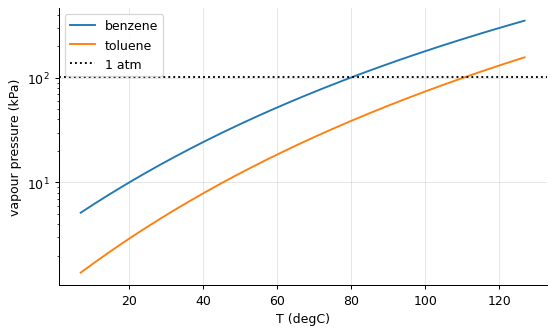

In [2]:
for name in ("benzene", "toluene", "ethanol", "water"):
    A, B, C, rng_, V = vle.ANTOINE[name]
    print(f"{name:<9} log10 P/mmHg = {A} - {B}/({C} + T/degC)   valid {rng_[0]}..{rng_[1]} degC   boiling point {vle.boiling_point(name)-273.15:.1f} degC")
T = np.linspace(280, 400, 200)
for name in ("benzene", "toluene"):
    plt.semilogy(T - 273.15, vle.antoine_pressure(name, T) / 1e3, label=name)
plt.axhline(101.325, color="k", ls=":", label="1 atm"); plt.xlabel("T (degC)"); plt.ylabel("vapour pressure (kPa)"); plt.legend(); plt.show()

Three constants per compound reproduce the vapour pressure over a hundred degrees to better than a percent,
and the temperature at which the curve crosses 1 atm is the normal boiling point. The library's table checks
its boiling points against NIST to within a kelvin - the first thing one should verify before trusting any
constants copied from a handbook.

## Mole fractions, balances and the lever rule

benzene balance: D = F (zF - xB)/(xD - xB) = 44.4 kmol/h, B = 55.6 kmol/h; benzene recovery in the distillate 93.8%


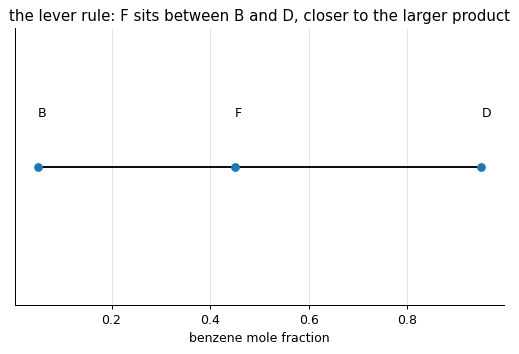

In [3]:
F, zF = 100.0, 0.45                                                 # kmol/h of feed, benzene mole fraction
xD, xB = 0.95, 0.05
D = F * (zF - xB) / (xD - xB)
print(f"benzene balance: D = F (zF - xB)/(xD - xB) = {D:.1f} kmol/h, B = {F - D:.1f} kmol/h; benzene recovery in the distillate {D*xD/(F*zF):.1%}")
xs = np.array([xB, zF, xD])
plt.plot(xs, [0, 0, 0], "k-"); plt.plot(xs, [0, 0, 0], "o"); plt.text(xB, 0.02, "B"); plt.text(zF, 0.02, "F"); plt.text(xD, 0.02, "D"); plt.yticks([]); plt.xlabel("benzene mole fraction"); plt.title("the lever rule: F sits between B and D, closer to the larger product"); plt.show()

Every separation is a material balance first: the feed splits into products whose compositions bracket it,
and the amounts follow from the lever rule. The recovery - what fraction of a component ends up where it
should - is the number a plant is paid for.

## Root finding and quadrature

In [4]:
P = 101325.0
# bubble point of a 50/50 benzene-toluene liquid: sum x_i Psat_i = P
T_b = optimize.brentq(lambda T: 0.5 * vle.antoine_pressure("benzene", T) + 0.5 * vle.antoine_pressure("toluene", T) - P, 300, 400)
print(f"bubble point of 50/50 benzene-toluene: {T_b - 273.15:.1f} degC (library: {vle.bubble_T(('benzene', 'toluene'), 0.5, ideal=True) - 273.15:.1f})")
# a PFR-like integral the course will meet as the number of transfer units: int dy/(y - y*)
ntu, _ = integrate.quad(lambda y: 1 / (y - 0.5 * y), 0.002, 0.02)
print(f"a transfer-unit integral by quadrature: {ntu:.3f} (analytic 2 ln 10 = {2*np.log(10):.3f})")

bubble point of 50/50 benzene-toluene: 92.1 degC (library: 92.1)
a transfer-unit integral by quadrature: 4.605 (analytic 2 ln 10 = 4.605)


`brentq` finds the temperature at which a sum of vapour pressures equals the total pressure - the bubble
point - and `quad` evaluates the integrals that size packed towers. The library uses the same two tools
behind every function, so a hand calculation with them is always available as a check.

## Diagrams: the x-y plot

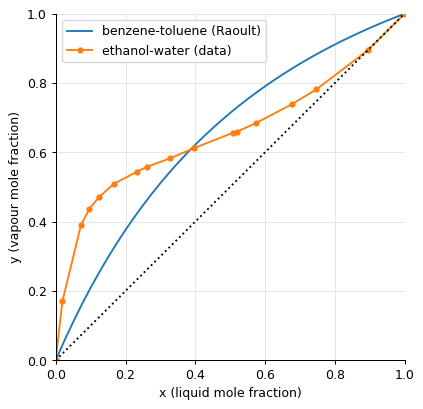

Ethanol-water VLE at 1 atm (Carey & Lewis 1932, via Perry's).


In [5]:
d = pd.read_csv(datasets.path("vle_ethanol_water.csv"), comment="#")
xy_bt = vle.xy(("benzene", "toluene"), n=41, ideal=True)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(xy_bt["x"], xy_bt["y"], label="benzene-toluene (Raoult)")
ax.plot(d.x_ethanol, d.y_ethanol, "o-", ms=4, label="ethanol-water (data)")
ax.plot([0, 1], [0, 1], "k:"); ax.set(xlabel="x (liquid mole fraction)", ylabel="y (vapour mole fraction)", xlim=(0, 1), ylim=(0, 1)); ax.legend(); plt.show()
print(datasets.describe("vle_ethanol_water.csv"))

The x-y diagram is the working drawing of distillation: the further the curve from the diagonal, the easier
the separation. Benzene-toluene bows uniformly; ethanol-water bows strongly at low ethanol and collapses onto
the diagonal at 89 mol % - the azeotrope, where distillation stops. Everything in notebooks 01-05 is built on
this picture.

## The course data

In [6]:
for name in datasets.available():
    print(f"{name:<36} {datasets.describe(name)[:88]}")

breakthrough_curve.csv               Laboratory fixed-bed breakthrough curve (Bohart-Adams, 2 % noise, one contaminated sampl
csd_msmpr.csv                        Crystal size distribution from an MSMPR crystalliser (5 % noise).
drying_curve.csv                     Tray-drying curve of a filter cake (constant and falling rate, 1.5 % noise).
gas_permeabilities.csv               Gas permeabilities (Barrer) of six membrane polymers (Baker; Robeson).
isotherm_phenol_carbon.csv           Phenol on activated carbon: batch isotherm points (Langmuir, 4 % noise).
plant_column_benzene_toluene.csv     30 days of benzene-toluene column data with unit faults and a retrofit target (project).
solubility.csv                       Solubility of eight salts in water, 0-100 degC (CRC Handbook).
ternary_acetic_water_ether.csv       Tie lines of acetic acid - water - isopropyl ether at 20 degC (Treybal / Seader).
vle_ethanol_water.csv                Ethanol-water VLE at 1 atm (Carey & Lewis 1932, via Perry

Literature tables with their sources (VLE data, permeabilities, solubilities, tie lines) and pseudo-experimental
files generated from the library's own models with stated noise and faults; the project of notebook 17
works from a month of column data, faults included, to a retrofit proposal.

## Inside the algorithm: the Antoine equation

In [7]:
A, B, C, _, _ = vle.ANTOINE["benzene"]
T_ = 353.25
print("by hand:", 10 ** (A - B / (C + T_ - 273.15)) * 133.322, "Pa; library:", vle.antoine_pressure("benzene", T_))

by hand: 101324.74071751292 Pa; library: 101325.02039757012


## Exercises
1. Compute the boiling points of every compound in the Antoine table and rank them. Which pairs of adjacent boilers would be the hardest to separate by distillation, and why does a boiling-point difference not tell the whole story?
2. A feed of 200 kmol/h with 0.6 benzene is split into a distillate of 0.98 and a bottoms of 0.02. Compute D, B and the recovery of each component in its product, and repeat for a distillate of 0.999 - how much more benzene is lost to the bottoms when the top is made purer at fixed D?
3. **Implement it yourself:** write a bubble-point function for any binary with Raoult's law using brentq and compare with `vle.bubble_T` for three compositions of benzene-toluene.